# AI-Powered Sentiment Analysis: Notebook

Workflow: load and clean the data, explore it, preprocess the text, extract BoW/TF-IDF features,
train and compare models, evaluate on a held-out test set, tune with grouped cross-validation, and save the pipeline.
The Streamlit app (`app.py`) loads the saved pipeline and does not retrain.

In [1]:
import os
import sys
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, auc)
from sklearn.preprocessing import label_binarize

sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
from text_utils import clean_text

FIG_DIR = os.path.join("..", "reports", "figures")
MODEL_DIR = os.path.join("..", "models")
REPORT_DIR = os.path.join("..", "reports")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
RANDOM_STATE = 42
LABELS = ["Negative", "Neutral", "Positive"]
COLORS = {"Negative": "#C44E52", "Neutral": "#8C8C8C", "Positive": "#4C9F70"}

## Step 1: Data understanding and cleaning

In [2]:
df = pd.read_csv(os.path.join("..", "data", "reviews.csv"))
print("Shape:", df.shape)
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate review_id:", df["review_id"].duplicated().sum())
print("Empty or whitespace-only reviews:", (df["review_text"].str.strip() == "").sum())
df.head()

Shape: (10000, 5)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10000 non-null  int64
 1   review_text  10000 non-null  str  
 2   sentiment    10000 non-null  str  
 3   category     10000 non-null  str  
 4   source       10000 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.5 MB

Missing values per column:
 review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64

Exact duplicate rows: 0
Duplicate review_id: 0
Empty or whitespace-only reviews: 0


,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store


In [3]:
print(df["sentiment"].value_counts())
print("\nUnique review texts:", df["review_text"].nunique(), "of", len(df))
labels_per_text = df.groupby("review_text")["sentiment"].nunique()
print("Texts that carry more than one label:", (labels_per_text > 1).sum())
print("Copies per text (min / median / max):",
      df["review_text"].value_counts().min(), df["review_text"].value_counts().median(),
      df["review_text"].value_counts().max())

sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64

Unique review texts: 300 of 10000
Texts that carry more than one label: 0
Copies per text (min / median / max): 21 33.0 52


**Findings**
- No missing values, no duplicate rows, no duplicate IDs, no empty reviews, so no rows are dropped.
- Classes are balanced (about 3,333 each).
- Only **300 unique review texts** exist across 10,000 rows, about 33 copies each, and every text has exactly one label.

**Why this matters:** a random train/test split would put copies of the same sentence on both sides,
which could inflate test scores. The rest of this notebook splits **by review text** (a group), so no text
appears in both train and test. Step 4 checks the effect on this data.

## Step 2: Exploratory data analysis

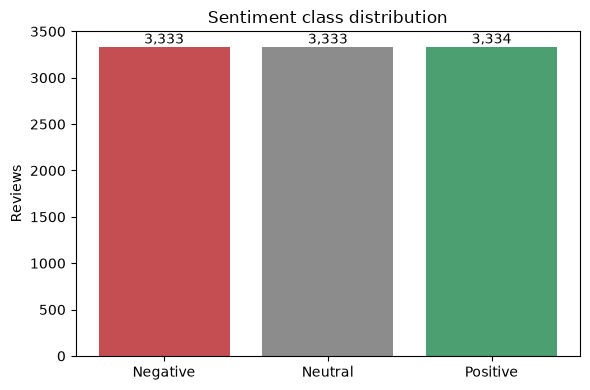

In [4]:
counts = df["sentiment"].value_counts().reindex(LABELS)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=[COLORS[l] for l in counts.index])
ax.set_title("Sentiment class distribution")
ax.set_ylabel("Reviews")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "class_distribution.png"), dpi=120)
plt.show()

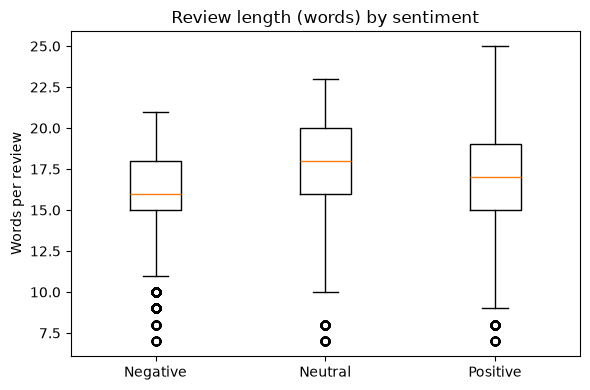

            count  mean  std  min   25%   50%   75%   max
sentiment                                                
Negative   3333.0  15.5  3.3  7.0  15.0  16.0  18.0  21.0
Neutral    3333.0  17.0  4.1  7.0  16.0  18.0  20.0  23.0
Positive   3334.0  16.5  4.2  7.0  15.0  17.0  19.0  25.0


In [5]:
df["n_words"] = df["review_text"].str.split().str.len()
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([df.loc[df["sentiment"] == l, "n_words"] for l in LABELS])
ax.set_xticks(range(1, len(LABELS) + 1), LABELS)
ax.set_title("Review length (words) by sentiment")
ax.set_ylabel("Words per review")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "review_length_by_sentiment.png"), dpi=120)
plt.show()
print(df.groupby("sentiment")["n_words"].describe().round(1))

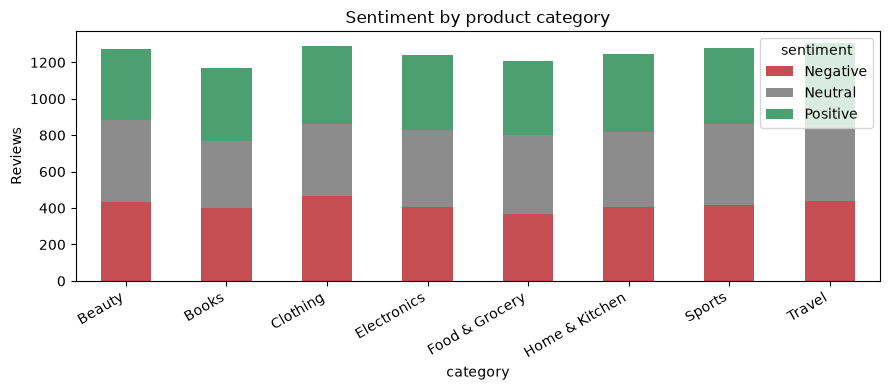

sentiment        Negative  Neutral  Positive
source                                      
Customer Survey     0.335    0.330     0.335
Mobile App          0.335    0.330     0.335
Online Store        0.361    0.323     0.316
Website             0.301    0.351     0.348


In [6]:
ct = pd.crosstab(df["category"], df["sentiment"])[LABELS]
ax = ct.plot(kind="bar", stacked=True, figsize=(9, 4), color=[COLORS[l] for l in LABELS])
ax.set_title("Sentiment by product category")
ax.set_ylabel("Reviews")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sentiment_by_category.png"), dpi=120)
plt.show()
print(pd.crosstab(df["source"], df["sentiment"], normalize="index")[LABELS].round(3))

In [7]:
# Most frequent words per class, after the same cleaning used for modelling
for label in LABELS:
    texts = df.loc[df["sentiment"] == label, "review_text"].map(clean_text)
    vec = CountVectorizer(stop_words="english")  # display only: hides "the", "and", etc.
    counts_ = np.asarray(vec.fit_transform(texts).sum(axis=0)).ravel()
    top = pd.Series(counts_, index=vec.get_feature_names_out()).nlargest(12)
    print(f"{label}: " + ", ".join(top.index))

Negative: experience, frustrating, recommend, disappointed, product, buy, based, far, overall, purchase, does, use
Neutral: product, use, used, evaluating, benefit, issue, observation, particular, stands, form, opinion, strong
Positive: experience, product, overall, recommend, satisfied, quality, far, good, looking, type, buying, consider


**Observations:** the classes have equal size, reviews are short (about 15 to 17 words), and category and source
are spread evenly, so they carry no obvious sentiment signal.

Top words (stopwords hidden here only): Positive is led by "satisfied", "quality", "good"; Negative by
"frustrating", "disappointed"; Neutral by hedging or factual words ("evaluating", "opinion", "observation").
"recommend" appears in both the Positive and Negative lists, which is why short phrases such as
"would not recommend" need bigrams and the "not" token, not just single words.

## Step 3: Text preprocessing

Each step is chosen for a reason:
- **Lowercasing:** "Good" and "good" should map to the same feature.
- **Expanding "n't" to "not":** negation flips meaning ("would not recommend"). Keeping it as a token matters.
- **Removing digits and punctuation:** they add noise with little sentiment value in these reviews.
- **Not removing stopwords:** standard English stopword lists contain "not", "no" and "very", which carry sentiment.
- **Not stemming or lemmatising:** the vocabulary is small and the phrasing is consistent, so the gain is small
  and it can blur words like "frustrating" and "frustrated". Bigrams in Step 5 capture short phrases instead.

In [8]:
sample = df["review_text"].iloc[1]
print("Raw:    ", sample)
print("Cleaned:", clean_text(sample))
print("Raw:    ", "The product doesn't work, I won't buy again!")
print("Cleaned:", clean_text("The product doesn't work, I won't buy again!"))

Raw:     The item is uncomfortable to use and poorly designed. I would not buy it again.
Cleaned: the item is uncomfortable to use and poorly designed i would not buy it again
Raw:     The product doesn't work, I won't buy again!
Cleaned: the product does not work i wo not buy again


## Step 4: Train/test split (grouped by review text) and leakage check

In [9]:
X = df["review_text"]
y = df["sentiment"]
groups = df["review_text"].factorize()[0]

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups[train_idx]

print("Train:", len(X_train), "| Test:", len(X_test))
print("Texts shared between train and test:", len(set(X_train) & set(X_test)))
print("Test class balance:\n", y_test.value_counts())

Train: 8000 | Test: 2000
Texts shared between train and test: 0
Test class balance:
 sentiment
Neutral     668
Positive    666
Negative    666
Name: count, dtype: int64


In [10]:
# For comparison only: a plain stratified random split leaks duplicated texts
X_tr_n, X_te_n, y_tr_n, y_te_n = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
leaky = Pipeline([("vec", TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2))),
                  ("clf", LogisticRegression(max_iter=1000))]).fit(X_tr_n, y_tr_n)
print("Random-split test accuracy (comparison only):", round(accuracy_score(y_te_n, leaky.predict(X_te_n)), 4))

Random-split test accuracy (comparison only): 1.0


**Result:** the random split also scores 1.0, so grouping does not change the number on this data.
The grouped split is still the correct protocol: it guarantees no text is seen twice, and it stays valid
if the dataset is extended with unique reviews. The near-perfect scores are discussed in the report.

## Steps 5 and 7: Feature extraction, model comparison and tuning

One `GridSearchCV` covers the whole design space:
- **Features:** Bag of Words (`CountVectorizer`) vs TF-IDF (`TfidfVectorizer`), unigrams vs uni+bigrams.
- **Models:** Logistic Regression (C) and Multinomial Naive Bayes (alpha). Both give class probabilities for the app.
- **Validation:** 5-fold `StratifiedGroupKFold` on the training portion, so folds never split a text group.
- **Metric:** macro F1, which weights all three classes equally.

In [11]:
pipe = Pipeline([
    ("vec", TfidfVectorizer(preprocessor=clean_text)),
    ("clf", LogisticRegression(max_iter=1000)),
])

vectorizers = [TfidfVectorizer(preprocessor=clean_text), CountVectorizer(preprocessor=clean_text)]
param_grid = [
    {"vec": vectorizers,
     "vec__ngram_range": [(1, 1), (1, 2)],
     "clf": [LogisticRegression(max_iter=1000)],
     "clf__C": [0.1, 1, 10]},
    {"vec": vectorizers,
     "vec__ngram_range": [(1, 1), (1, 2)],
     "clf": [MultinomialNB()],
     "clf__alpha": [0.1, 0.5, 1.0]},
]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipe, param_grid, cv=cv,
                      scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
                      refit="f1_macro")
search.fit(X_train, y_train, groups=groups_train)

results = pd.DataFrame(search.cv_results_)
results["classifier"] = results["param_clf"].map(lambda c: type(c).__name__)
results["vectorizer"] = results["param_vec"].map(lambda v: type(v).__name__.replace("Vectorizer", ""))
results["setting"] = results.apply(
    lambda r: f"ngram={r['param_vec__ngram_range']}, " +
              (f"C={r['param_clf__C']}" if r["classifier"] == "LogisticRegression" else f"alpha={r['param_clf__alpha']}"),
    axis=1)
cols = ["classifier", "vectorizer", "setting", "mean_test_f1_macro", "std_test_f1_macro", "mean_test_accuracy"]
print("Top 10 configurations (5-fold grouped CV):")
results.sort_values("rank_test_f1_macro")[cols].head(10).round(4)

Top 10 configurations (5-fold grouped CV):


,classifier,vectorizer,setting,mean_test_f1_macro,std_test_f1_macro,mean_test_accuracy
15,MultinomialNB,Count,"ngram=(1, 2), alpha=0.1",0.9959,0.0083,0.9959
13,MultinomialNB,Tfidf,"ngram=(1, 2), alpha=0.1",0.9959,0.0083,0.9959
14,MultinomialNB,Count,"ngram=(1, 1), alpha=0.1",0.9959,0.0083,0.9959
23,MultinomialNB,Count,"ngram=(1, 2), alpha=1.0",0.9959,0.0083,0.9959
21,MultinomialNB,Tfidf,"ngram=(1, 2), alpha=1.0",0.9959,0.0083,0.9959
19,MultinomialNB,Count,"ngram=(1, 2), alpha=0.5",0.9959,0.0083,0.9959
18,MultinomialNB,Count,"ngram=(1, 1), alpha=0.5",0.9959,0.0083,0.9959
17,MultinomialNB,Tfidf,"ngram=(1, 2), alpha=0.5",0.9959,0.0083,0.9959
22,MultinomialNB,Count,"ngram=(1, 1), alpha=1.0",0.9959,0.0083,0.9959
16,MultinomialNB,Tfidf,"ngram=(1, 1), alpha=0.5",0.9932,0.0135,0.9932


In [12]:
print("Best family per feature representation (mean CV macro F1):")
print(results.groupby(["classifier", "vectorizer"])["mean_test_f1_macro"].max().round(4))
print("\nSelected:", type(search.best_estimator_.named_steps["vec"]).__name__,
      search.best_estimator_.named_steps["vec"].ngram_range, "+",
      type(search.best_estimator_.named_steps["clf"]).__name__)
print("Best CV macro F1:", round(search.best_score_, 4))

Best family per feature representation (mean CV macro F1):
classifier          vectorizer
LogisticRegression  Count         0.9912
                    Tfidf         0.9922
MultinomialNB       Count         0.9959
                    Tfidf         0.9959
Name: mean_test_f1_macro, dtype: float64

Selected: TfidfVectorizer (1, 2) + MultinomialNB
Best CV macro F1: 0.9959


## Step 6: Evaluation on the held-out test set

In [13]:
best = search.best_estimator_
y_pred = best.predict(X_test)
y_proba = best.predict_proba(X_test)
classes = list(best.classes_)

acc = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, labels=LABELS, digits=4, output_dict=True)
print(classification_report(y_test, y_pred, labels=LABELS, digits=4))
print("Accuracy:", round(acc, 4))

              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000       666
     Neutral     1.0000    1.0000    1.0000       668
    Positive     1.0000    1.0000    1.0000       666

    accuracy                         1.0000      2000
   macro avg     1.0000    1.0000    1.0000      2000
weighted avg     1.0000    1.0000    1.0000      2000

Accuracy: 1.0


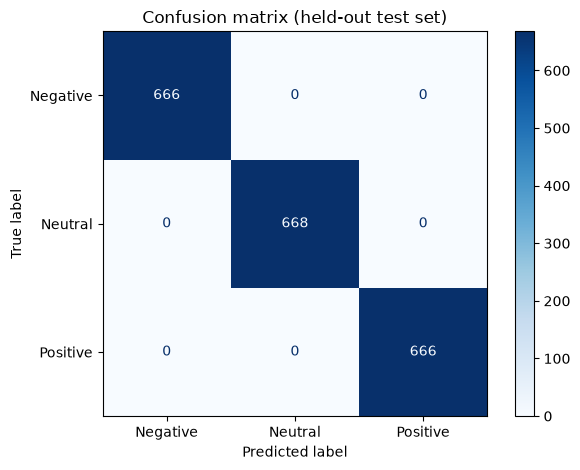

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=LABELS)
disp = ConfusionMatrixDisplay(cm, display_labels=LABELS)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (held-out test set)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrix.png"), dpi=120)
plt.show()

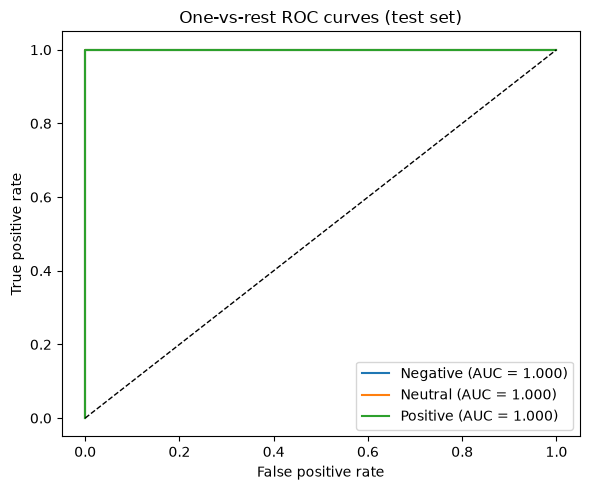

{np.str_('Negative'): 1.0, np.str_('Neutral'): 1.0, np.str_('Positive'): 1.0} macro AUC: 1.0


In [15]:
y_bin = label_binarize(y_test, classes=classes)
fig, ax = plt.subplots(figsize=(6, 5))
aucs = {}
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
    aucs[c] = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{c} (AUC = {aucs[c]:.3f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("One-vs-rest ROC curves (test set)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "roc_curves.png"), dpi=120)
plt.show()
print({k: round(v, 4) for k, v in aucs.items()}, "macro AUC:", round(float(np.mean(list(aucs.values()))), 4))

## Step 8: Save the pipeline and metrics

In [16]:
MODEL_PATH = os.path.join(MODEL_DIR, "sentiment_pipeline.pkl")
joblib.dump(best, MODEL_PATH)

# Check that the saved file gives identical predictions
reloaded = joblib.load(MODEL_PATH)
assert (reloaded.predict(X_test) == y_pred).all()

metrics = {
    "test_accuracy": round(acc, 4),
    "test_macro_f1": round(report["macro avg"]["f1-score"], 4),
    "per_class": {l: {k: round(report[l][k], 4) for k in ["precision", "recall", "f1-score"]} for l in LABELS},
    "roc_auc_ovr": {k: round(v, 4) for k, v in aucs.items()},
    "macro_roc_auc": round(float(np.mean(list(aucs.values()))), 4),
    "cv_best_macro_f1": round(search.best_score_, 4),
    "selected_vectorizer": type(best.named_steps["vec"]).__name__,
    "selected_ngram_range": list(best.named_steps["vec"].ngram_range),
    "selected_classifier": type(best.named_steps["clf"]).__name__,
    "selected_params": {k: v for k, v in best.named_steps["clf"].get_params().items() if k in ("C", "alpha")},
    "random_split_leaky_accuracy_reference": round(accuracy_score(y_te_n, leaky.predict(X_te_n)), 4),
}
with open(os.path.join(REPORT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
print("Saved", MODEL_PATH)
print(json.dumps(metrics, indent=2))

Saved ..\models\sentiment_pipeline.pkl
{
  "test_accuracy": 1.0,
  "test_macro_f1": 1.0,
  "per_class": {
    "Negative": {
      "precision": 1.0,
      "recall": 1.0,
      "f1-score": 1.0
    },
    "Neutral": {
      "precision": 1.0,
      "recall": 1.0,
      "f1-score": 1.0
    },
    "Positive": {
      "precision": 1.0,
      "recall": 1.0,
      "f1-score": 1.0
    }
  },
  "roc_auc_ovr": {
    "Negative": 1.0,
    "Neutral": 1.0,
    "Positive": 1.0
  },
  "macro_roc_auc": 1.0,
  "cv_best_macro_f1": 0.9959,
  "selected_vectorizer": "TfidfVectorizer",
  "selected_ngram_range": [
    1,
    2
  ],
  "selected_classifier": "MultinomialNB",
  "selected_params": {
    "alpha": 0.1
  },
  "random_split_leaky_accuracy_reference": 1.0
}


## Step 9: Streamlit application

Run `streamlit run app.py` from the project root. It loads `models/sentiment_pipeline.pkl`, takes a review,
and shows the predicted sentiment with class probabilities. Nothing is retrained at start-up.